# Data Preprocessing & Time Series Preparation

This notebook prepares the retail sales data for time series forecasting.

The goal is to check data quality, validate dates, investigate missing observations, and create a consistent daily sales series for the next stage of the project.

## 1. Load the Dataset

Load the training dataset and check its structure before starting the preprocessing work.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path


class DataLoader:
    """Load the retail sales dataset."""

    def __init__(self, data_dir="../datasets"):
        self.data_dir = Path(data_dir)

    def load_csv(self, filename):
        file_path = self.data_dir / filename

        if not file_path.exists():
            raise FileNotFoundError(
                f"Could not find the file: {file_path.resolve()}"
            )

        data = pd.read_csv(file_path)

        print(f"Loaded {filename} successfully.")
        return data


loader = DataLoader()
train = loader.load_csv("train.csv")

print("Dataset shape:", train.shape)
display(train.head())

Loaded train.csv successfully.
Dataset shape: (3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 2. Initial Data Quality Checks

Inspect the columns, data types, missing values, and duplicate records before preparing the time series.

In [2]:
class DataQualityChecker:
    """Run basic data quality checks."""

    def __init__(self, data):
        self.data = data

    def show_columns_and_types(self):
        print("Columns and data types:")
        display(
            self.data.dtypes.rename("data_type").to_frame()
        )

    def show_missing_values(self):
        print("Missing values:")
        missing = self.data.isnull().sum()
        display(missing.rename("missing_count").to_frame())

    def show_duplicate_rows(self):
        duplicate_count = self.data.duplicated().sum()

        print(f"Duplicate rows: {duplicate_count}")

    def show_date_information(self):
        print("Date column data type:", self.data["date"].dtype)
        print("Earliest date:", self.data["date"].min())
        print("Latest date:", self.data["date"].max())
        
    def convert_date_column(self):
        self.data["date"] = pd.to_datetime(
            self.data["date"],
            errors="raise"
        )

        print("Date column converted to datetime.")
        print("Data type:", self.data["date"].dtype)

    def check_date_order(self):
        is_sorted = self.data["date"].is_monotonic_increasing

        print("Dates already in chronological order:", is_sorted)

    def show_date_range(self):
        print("Start date:", self.data["date"].min())
        print("End date:", self.data["date"].max())
        print("Unique dates:", self.data["date"].nunique())


quality_checker = DataQualityChecker(train)

quality_checker.show_columns_and_types()
quality_checker.show_missing_values()
quality_checker.show_duplicate_rows()
quality_checker.show_date_information()

Columns and data types:


,data_type
id,int64
date,object
store_nbr,int64
family,object
sales,float64
onpromotion,int64


Missing values:


,missing_count
id,0
date,0
store_nbr,0
family,0
sales,0
onpromotion,0


Duplicate rows: 0
Date column data type: object
Earliest date: 2013-01-01
Latest date: 2017-08-15


## 3. Date Validation

Convert the date column to datetime format and check whether the dates are valid and chronologically consistent.

In [3]:
quality_checker.convert_date_column()
quality_checker.check_date_order()
quality_checker.show_date_range()

Date column converted to datetime.
Data type: datetime64[ns]
Dates already in chronological order: True
Start date: 2013-01-01 00:00:00
End date: 2017-08-15 00:00:00
Unique dates: 1684


## 4. Create the Daily Sales Series

Aggregate sales across all stores and product families to create one total sales value per day. This will be the initial forecasting target.

In [4]:
class TimeSeriesPreprocessor:
    """Prepare sales data for time series forecasting."""

    def __init__(self, data):
        self.data = data

    def create_daily_sales(self):
        daily_sales = (
            self.data.groupby("date", as_index=False)["sales"]
            .sum()
            .sort_values("date")
            .reset_index(drop=True)
        )

        daily_sales = daily_sales.rename(
            columns={"sales": "daily_sales"}
        )

        return daily_sales
    
    def check_missing_dates(self, daily_sales):
        full_dates = pd.date_range(
            start=daily_sales["date"].min(),
            end=daily_sales["date"].max(),
            freq="D"
        )

        observed_dates = pd.DatetimeIndex(daily_sales["date"])

        missing_dates = full_dates.difference(observed_dates)

        print("Expected calendar days:", len(full_dates))
        print("Observed dates:", len(observed_dates))
        print("Missing dates:", len(missing_dates))

        if len(missing_dates) > 0:
            print("\nFirst missing dates:")
            display(pd.DataFrame({"missing_date": missing_dates[:10]}))
        else:
            print("No missing calendar dates found.")

        return missing_dates
    
    def create_complete_daily_series(self, daily_sales):
        full_dates = pd.date_range(
            start=daily_sales["date"].min(),
            end=daily_sales["date"].max(),
            freq="D"
        )

        complete_sales = (
            daily_sales
            .set_index("date")
            .reindex(full_dates)
            .rename_axis("date")
            .reset_index()
        )

        complete_sales["daily_sales"] = (
            complete_sales["daily_sales"].fillna(0)
        )

        print("Complete daily series created.")
        print("Rows:", len(complete_sales))
        print(
            "Missing values:",
            complete_sales["daily_sales"].isna().sum()
        )

        return complete_sales
    
    def validate_daily_series(self, daily_sales):
        print("Rows:", len(daily_sales))
        print("Missing values:")
        display(daily_sales.isna().sum().to_frame("missing_count"))

        print(
            "Duplicate dates:",
            daily_sales["date"].duplicated().sum()
        )

        print(
            "Chronological order:",
            daily_sales["date"].is_monotonic_increasing
        )

        print(
            "Negative sales values:",
            (daily_sales["daily_sales"] < 0).sum()
        )

        date_gaps = daily_sales["date"].diff().dropna()
        print(
            "All intervals are one day:",
            date_gaps.eq(pd.Timedelta(days=1)).all()
        )

        print("\nSales summary:")
        display(daily_sales["daily_sales"].describe())


preprocessor = TimeSeriesPreprocessor(train)

daily_sales = preprocessor.create_daily_sales()

print("Daily sales shape:", daily_sales.shape)
display(daily_sales.head())
display(daily_sales.tail())

Daily sales shape: (1684, 2)


,date,daily_sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


,date,daily_sales
1679,2017-08-11,826373.722022
1680,2017-08-12,792630.535079
1681,2017-08-13,865639.677471
1682,2017-08-14,760922.406081
1683,2017-08-15,762661.935939


## 5. Check for Missing Dates

Compare the observed dates with a complete daily calendar to identify any dates that are missing from the aggregated sales series.

In [5]:
missing_dates = preprocessor.check_missing_dates(daily_sales)

Expected calendar days: 1688
Observed dates: 1684
Missing dates: 4

First missing dates:


,missing_date
0,2013-12-25
1,2014-12-25
2,2015-12-25
3,2016-12-25


## 6. Investigate Missing Dates

Check the holiday and event calendar to understand why the four missing dates may be absent from the sales data.

In [6]:
holidays = loader.load_csv("holidays_events.csv")

print("Holiday dataset shape:", holidays.shape)
display(holidays.head())

Loaded holidays_events.csv successfully.
Holiday dataset shape: (350, 6)


,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


In [7]:
holidays["date"] = pd.to_datetime(holidays["date"])

missing_dates_df = pd.DataFrame({
    "date": missing_dates
})

holiday_check = missing_dates_df.merge(
    holidays,
    on="date",
    how="left"
)

display(holiday_check)

,date,type,locale,locale_name,description,transferred
0,2013-12-25,Holiday,National,Ecuador,Navidad,False
1,2014-12-25,Holiday,National,Ecuador,Navidad,False
2,2015-12-25,Holiday,National,Ecuador,Navidad,False
3,2016-12-25,Holiday,National,Ecuador,Navidad,False


## 7. Create a Continuous Daily Series

Create a complete daily calendar and align the aggregated sales data to it. The four missing dates fall on national Christmas holidays in Ecuador, so zero sales will be used provisionally for these dates. This assumption will be documented and reviewed during modelling.

In [8]:
daily_sales_complete = preprocessor.create_complete_daily_series(
    daily_sales
)

display(daily_sales_complete.head())
display(daily_sales_complete.tail())

print(
    "Zero-sales dates:",
    daily_sales_complete.loc[
        daily_sales_complete["daily_sales"] == 0,
        "date"
    ].tolist()
)

Complete daily series created.
Rows: 1688
Missing values: 0


,date,daily_sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


,date,daily_sales
1683,2017-08-11,826373.722022
1684,2017-08-12,792630.535079
1685,2017-08-13,865639.677471
1686,2017-08-14,760922.406081
1687,2017-08-15,762661.935939


Zero-sales dates: [Timestamp('2013-12-25 00:00:00'), Timestamp('2014-12-25 00:00:00'), Timestamp('2015-12-25 00:00:00'), Timestamp('2016-12-25 00:00:00')]


## 8. Validate the Prepared Series

Check the completed daily series for missing values, duplicate dates, negative sales, and consistent daily intervals.

In [9]:
preprocessor.validate_daily_series(daily_sales_complete)

Rows: 1688
Missing values:


,missing_count
date,0
daily_sales,0


Duplicate dates: 0
Chronological order: True
Negative sales values: 0
All intervals are one day: True

Sales summary:


count    1.688000e+03
mean     6.360456e+05
std      2.361766e+05
min      0.000000e+00
25%      4.408053e+05
50%      6.316926e+05
75%      7.855799e+05
max      1.463084e+06
Name: daily_sales, dtype: float64

## 9. Visualise the Prepared Daily Sales Series

Plot the complete daily sales series to inspect its overall trend, fluctuations, and unusual values before saving it for modelling.

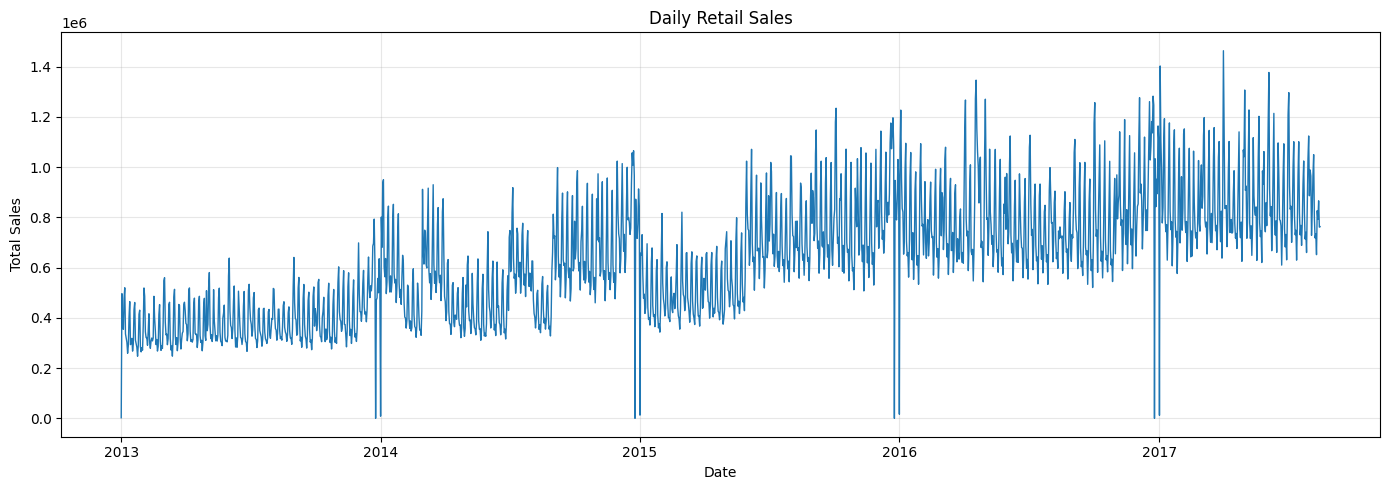

In [10]:
import matplotlib.pyplot as plt


class TimeSeriesVisualizer:
    """Create visualisations of the prepared time series."""

    def __init__(self, data):
        self.data = data

    def plot_daily_sales(self):
        plt.figure(figsize=(14, 5))

        plt.plot(
            self.data["date"],
            self.data["daily_sales"],
            linewidth=1
        )

        plt.title("Daily Retail Sales")
        plt.xlabel("Date")
        plt.ylabel("Total Sales")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig("../outputs/figures/07_daily_sales_plot.png", dpi=300)
        plt.show()


visualizer = TimeSeriesVisualizer(daily_sales_complete)
visualizer.plot_daily_sales()

## 10. Save the Prepared Dataset

Save the continuous daily sales series as a CSV file so it can be reused in the forecasting stage.

In [11]:
from pathlib import Path


class DatasetExporter:
    """Save prepared datasets to disk."""

    def __init__(self, output_dir="../outputs/processed"):
        self.output_dir = Path(output_dir)

    def save_csv(self, data, filename):
        self.output_dir.mkdir(parents=True, exist_ok=True)

        file_path = self.output_dir / filename
        data.to_csv(file_path, index=False)

        print(f"Dataset saved to: {file_path}")
        print(f"Rows saved: {len(data)}")

        return file_path


exporter = DatasetExporter()

processed_file = exporter.save_csv(
    daily_sales_complete,
    "daily_sales.csv"
)

Dataset saved to: ..\outputs\processed\daily_sales.csv
Rows saved: 1688


## 11. Verify the Exported Dataset

Reload the saved CSV and check its dimensions, columns, date range, and missing values.

In [12]:
saved_data = pd.read_csv(
    processed_file,
    parse_dates=["date"]
)

print("Saved dataset shape:", saved_data.shape)
print("Columns:", saved_data.columns.tolist())
print("Start date:", saved_data["date"].min())
print("End date:", saved_data["date"].max())
print("Missing values:", saved_data.isna().sum().sum())

print(
    "Matches prepared data:",
    saved_data.equals(daily_sales_complete)
)

display(saved_data.head())

Saved dataset shape: (1688, 2)
Columns: ['date', 'daily_sales']
Start date: 2013-01-01 00:00:00
End date: 2017-08-15 00:00:00
Missing values: 0
Matches prepared data: False


,date,daily_sales
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


In [13]:
print(
    "Dates match:",
    saved_data["date"].equals(daily_sales_complete["date"])
)

print(
    "Sales match within floating-point tolerance:",
    np.allclose(
        saved_data["daily_sales"],
        daily_sales_complete["daily_sales"],
        rtol=1e-9,
        atol=1e-6
    )
)

print(
    "Maximum absolute difference:",
    np.abs(
        saved_data["daily_sales"].to_numpy()
        - daily_sales_complete["daily_sales"].to_numpy()
    ).max()
)

Dates match: True
Sales match within floating-point tolerance: True
Maximum absolute difference: 2.3283064365386963e-10
